# 05 · Stage 5 — Posterior uncertainty

Stage 5 takes the optimum $a^*$ and the constraint run of Stage 4 and returns, for every edge and year, a posterior σ and a 95 % interval around $a^*$.

> **What this stage assumes**
> - **A1** The prior is Gaussian with a diagonal $\Sigma_a$; the constraints are observations of $G a$ (Eq. 3).
> - **A3** Hard rows hold exactly, so their variance is zero; soft rows carry $\sigma_c^2$.
> - **A5** σ is never dropped between stages: the prior σ of Stage 3 is the starting point here.
> - **A12** Results are year-local: each year is reduced on its own slice.
> - Copper's choice: its Stage 5 linearises the QP at the active set (a binding band becomes an equality, a binding lower bound pins its edge) and reports Birge-scaled intervals (ADR 0044; manuscript §3.1.7). The toy has no bands, hence no active set, and its intervals are the raw ones.

In [1]:
import json
import logging
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

from pysuto._conditioning import condition_prior, condition_sigma_c
from pysuto import acc_store
from pysuto.tutorial import toy
from pysuto.diag import UncPropDiag
from pysuto.registry import ConstraintRunRegistry, OptimRunRegistry, UncPropRunRegistry

RUNS = Path("runs")
PROC = RUNS / "proc"
pd.set_option("display.width", 140)
logging.disable(logging.INFO)

## Run Stage 5

Stage 4 left an opt run in `runs/`; Stage 5 propagates its uncertainty.

In [2]:
unc_id = toy.run_stage5(RUNS)
unc_reg = UncPropRunRegistry(str(PROC / "uncprop"))
unc = unc_reg.load(unc_id)
unc_meta = unc_reg.load_sidecar(unc_id)
opt_id = unc_meta["parents"]["upstream"]["opt_run_id"]
const_id = unc_meta["parents"]["upstream"]["const_run_id"]
const = ConstraintRunRegistry(str(PROC / "const")).load(const_id)
results = OptimRunRegistry(str(PROC / "opt")).load(opt_id)
print(unc_id, "propagates", opt_id)

uncprop_20261123_151913_714e8d7c propagates opt_20261123_151908_06e888ed


## Eq. (3)

Stage 4 gave one number per edge. Stage 5 asks how far each could have moved had the sources been drawn again. Model the prior as Gaussian, $a\sim N(a_0,\Sigma_a)$, and every row as an observation $G a = c$ with variance $\Sigma_c^{\mathrm{full}}$ (zero on hard rows). Gaussian conditioning gives the posterior covariance, the generalised-least-squares update of Byron (1978):

$$\Sigma_{a^*} = \Sigma_a - \Sigma_a G^\top S^{-1} G\,\Sigma_a,\qquad S = G\Sigma_a G^\top + \Sigma_c^{\mathrm{full}} \tag{3}$$

What is subtracted is what the rows tell us: a posterior variance is the prior variance minus a non-negative amount. So $\sigma_{a^*}\le\sigma_a$ on every edge; an edge no row touches keeps its prior σ.

Let us compute Eq. (3) by hand for 2003 and compare it with what Stage 5 stored. First the year's pieces, as in chapter 04.

In [3]:
year = "2003"
res = results[year]
cols, rows = np.asarray(res.cols_t), np.asarray(res.rows_t)
_, sigma_a = condition_prior(const.a_prior_global, const.sigma_a)
hard = const.row_meta["is_hard"].to_numpy().astype(bool)[rows]
sc = condition_sigma_c(np.asarray(const.timestep_data[year]["sigma_c"])[rows])
sc = np.where(hard, 0.0, sc)
G = const.G[rows][:, cols].toarray()
print(f"{year}: G {G.shape}; σ_c is 0 on {hard.sum()} hard rows")

2003: G (82, 84); σ_c is 0 on 39 hard rows


Forming $S^{-1}$ directly is numerically fragile here: σ_a ranges over twelve orders of magnitude. Stage 5 reads the same quantity off a factorisation of the whitened system $[G\Sigma_a^{1/2},\ \Sigma_c^{1/2}]$ (see the box below); the cell does the same with an SVD. A short function:

In [4]:
def posterior_sigma(G, sa, sc):
    M = np.hstack([G * sa, np.diag(sc)])
    _, s, Vt = np.linalg.svd(M, full_matrices=False)
    kappa = (Vt[s > 1e-10 * s[0], :len(sa)] ** 2).sum(0)
    return sa * np.sqrt(np.clip(1 - kappa, 0, None))

by_hand = posterior_sigma(G, sigma_a[cols], sc)
stored = unc.per_timestep[year].sigma_a_star
print(f"largest |by hand − Stage 5| = {np.abs(by_hand - stored).max():.1e} (largest σ_a* is {stored.max():.1f})")

largest |by hand − Stage 5| = 2.5e-05 (largest σ_a* is 102.5)


The hand computation and Stage 5 agree to within the rounding of the factorisation.

<details><summary>Going deeper: contraction, QR, and why not $S^{-1}$</summary>

Write $W=\Sigma_a^{1/2}$ and $B=GW$. Then $\Sigma_{a^*}=W\,(I-\kappa)\,W$ with $\kappa=B^\top(BB^\top+\Sigma_c^{\mathrm{full}})^{-1}B$, a projection: the *contraction* $\kappa_i\in[0,1]$ of edge $i$, and $\sigma_{a^*,i}^2=\sigma_{a,i}^2(1-\kappa_i)$. $\kappa_i=0$ means the rows tell us nothing about the edge; $\kappa_i=1$ means they pin it down. The projection is onto the row space of the whitened matrix $[B,\ \Sigma_c^{1/2}]$, whose diagonal one reads off a QR (Stage 5) or an SVD (the cell above) without ever forming $S$. Forming $S$ squares the condition number, and with σ from $10^{-6}$ to $10^{6}$ that puts the contraction outside $[0,1]$ on some edges.

**The hard-only limit.** Set $\Sigma_c$ to zero on every row. Then Eq. (3) reduces to Byron's (1978) closed form for pure equality constraints, $\Sigma_{a^*}=\Sigma_a-\Sigma_aG^\top(G\Sigma_aG^\top)^{-1}G\Sigma_a$, the posterior of a prior conditioned on $Ga=c$ exactly. The soft rows of the toy only soften this: each lets its edges move a little more than the hard limit allows, so the toy's σ lie between the prior's and Byron's.

**Why the toy has no active set.** Eq. (3) is exact for equality rows. Copper's QP also has inequality rows (hard non-negativity of every flow, ratio bands); where one binds at $a^*$, Stage 5 treats it as an equality, where it is slack it drops it, and a flow held at its lower bound gets $\sigma_{a^*}=0$ (ADR 0044). The toy registers no band, so its QP has equality rows only and there is nothing to choose: its Stage 5 is exactly Eq. (3). The sidecar says so, as the cell below shows. The price is that a toy posterior may put a flow below zero.
</details>

In [5]:
diagn = unc.per_timestep[year].diagnostics
print({k: diagn[k] for k in ("n_bound_active", "n_bands_binding", "n_hard_dependent", "n_rows_kept")})

{'n_bound_active': 0, 'n_bands_binding': 0, 'n_hard_dependent': 0, 'n_rows_kept': 82}


## σ shrinkage, prior to posterior

For every edge and year: the prior σ that went into Stage 4 and the posterior σ that comes out. All years in one table:

In [6]:
def shrinkage(unc, sigma_a):
    frames = [pd.DataFrame({"time": t, "edge_id": ts.cols_t, "sigma_prior": sigma_a[ts.cols_t],
                            "sigma_post": ts.sigma_a_star}) for t, ts in unc.per_timestep.items()]
    return pd.concat(frames, ignore_index=True)

shrink = shrinkage(unc, sigma_a)
shrink["ratio"] = shrink["sigma_post"] / shrink["sigma_prior"]
acc = acc_store.load("toy", storage_dir=str(PROC / "acc"))
shrink["edge"] = shrink["edge_id"].map(acc.edge_labels())
print(len(shrink), "edge-years")

420 edge-years


Which edges did the rows pin down most, and which least, in 2003? (Edges whose prior σ already sits at the floor, the pinned zeros of the satellite flows, cannot shrink and are left out.)

In [7]:
y = shrink[(shrink["time"] == year) & (shrink["sigma_prior"] > 1e-3)].sort_values("ratio")
pd.concat([y.head(4), y.tail(4)])[["edge", "sigma_prior", "sigma_post", "ratio"]]

,edge,sigma_prior,sigma_post,ratio
198,Milling|Portua → Tailings|Portua (Gross),748612.441082,14.750622,0.000020
184,Mining|Isla → WasteRock|Isla (Gross),939528.896449,34.498932,0.000037
197,Milling|Portua → Concentrate|Portua (Content),7486.351795,0.465020,0.000062
213,Concentrate|Portua → Smelting|Portua (Content),7486.351795,0.466877,0.000062
243,Metal|Montara → Stock|Montara (Content),0.003698,0.003634,0.982644
233,Smelting|Isla → Slag|Isla (Content),0.007745,0.007703,0.994499
225,Smelting|Montara → Slag|Montara (Content),0.004443,0.004421,0.994919
229,Smelting|Portua → Slag|Portua (Content),0.018207,0.018137,0.996180


A ratio near 0 is an edge the balances fix almost completely, usually one whose prior was nearly uninformative. A ratio near 1 is an edge the rows barely touch, so its feed (or its prior) speaks alone. The ratio is $\sqrt{1-\kappa}$.

## The intervals

Stage 5 stores $a^*\pm z_{0.975}\,\sigma_{a^*}$, clipped at a structural lower bound if the edge has one (the toy has none). Here are the intervals of the same edges in 2003.

In [8]:
ts = unc.per_timestep[year]
iv = pd.DataFrame({"edge_id": ts.cols_t, "a_star": res.F_opt, "lower": ts.lower, "upper": ts.upper})
iv["edge"] = [shrink.set_index(["time", "edge_id"]).at[(year, i), "edge"] for i in iv["edge_id"]]
iv.set_index("edge_id").loc[pd.concat([y.head(4), y.tail(4)])["edge_id"]][["edge", "a_star", "lower", "upper"]]

,edge,a_star,lower,upper
edge_id,,,,
154,Milling|Portua → Tailings|Portua (Gross),2.081463,-26.829225,30.992152
84,Mining|Isla → WasteRock|Isla (Gross),781.413740,713.797076,849.030404
145,Milling|Portua → Concentrate|Portua (Content),-0.696059,-1.607482,0.215364
225,Concentrate|Portua → Smelting|Portua (Content),-0.727969,-1.643031,0.187092
375,Metal|Montara → Stock|Montara (Content),0.053909,0.046786,0.061032
325,Smelting|Isla → Slag|Isla (Content),0.126452,0.111355,0.141549
285,Smelting|Montara → Slag|Montara (Content),0.069609,0.060944,0.078274
305,Smelting|Portua → Slag|Portua (Content),0.290644,0.255096,0.326192


In [9]:
lower = np.concatenate([ts.lower for ts in unc.per_timestep.values()])
below = int((lower < -1e-6).sum())
print(f"{below} of {len(shrink)} edge-years have a lower limit below zero")

117 of 420 edge-years have a lower limit below zero


Units are `kt` for `Gross` edges and `kt Content` for `Content` edges. These are intervals of the model under its stated σ; whether they hold the truth is a question for chapter 07.

## The diagnostic figures

`UncPropDiag` names its figures by plot id; the cell below asks for two. `UD-R-01` draws the contraction $\kappa$ against the defect $z$ of each edge-year; `UD-R-02` draws the prior and posterior bands over the years. The `timesteps` argument chooses the years pooled in the first figure.

   UD-R-01  → runs/figs/ud_r_01_contraction_shift.png  ✓


   UD-R-02  → runs/figs/ud_r_02_prior_posterior_bands.png  ✓


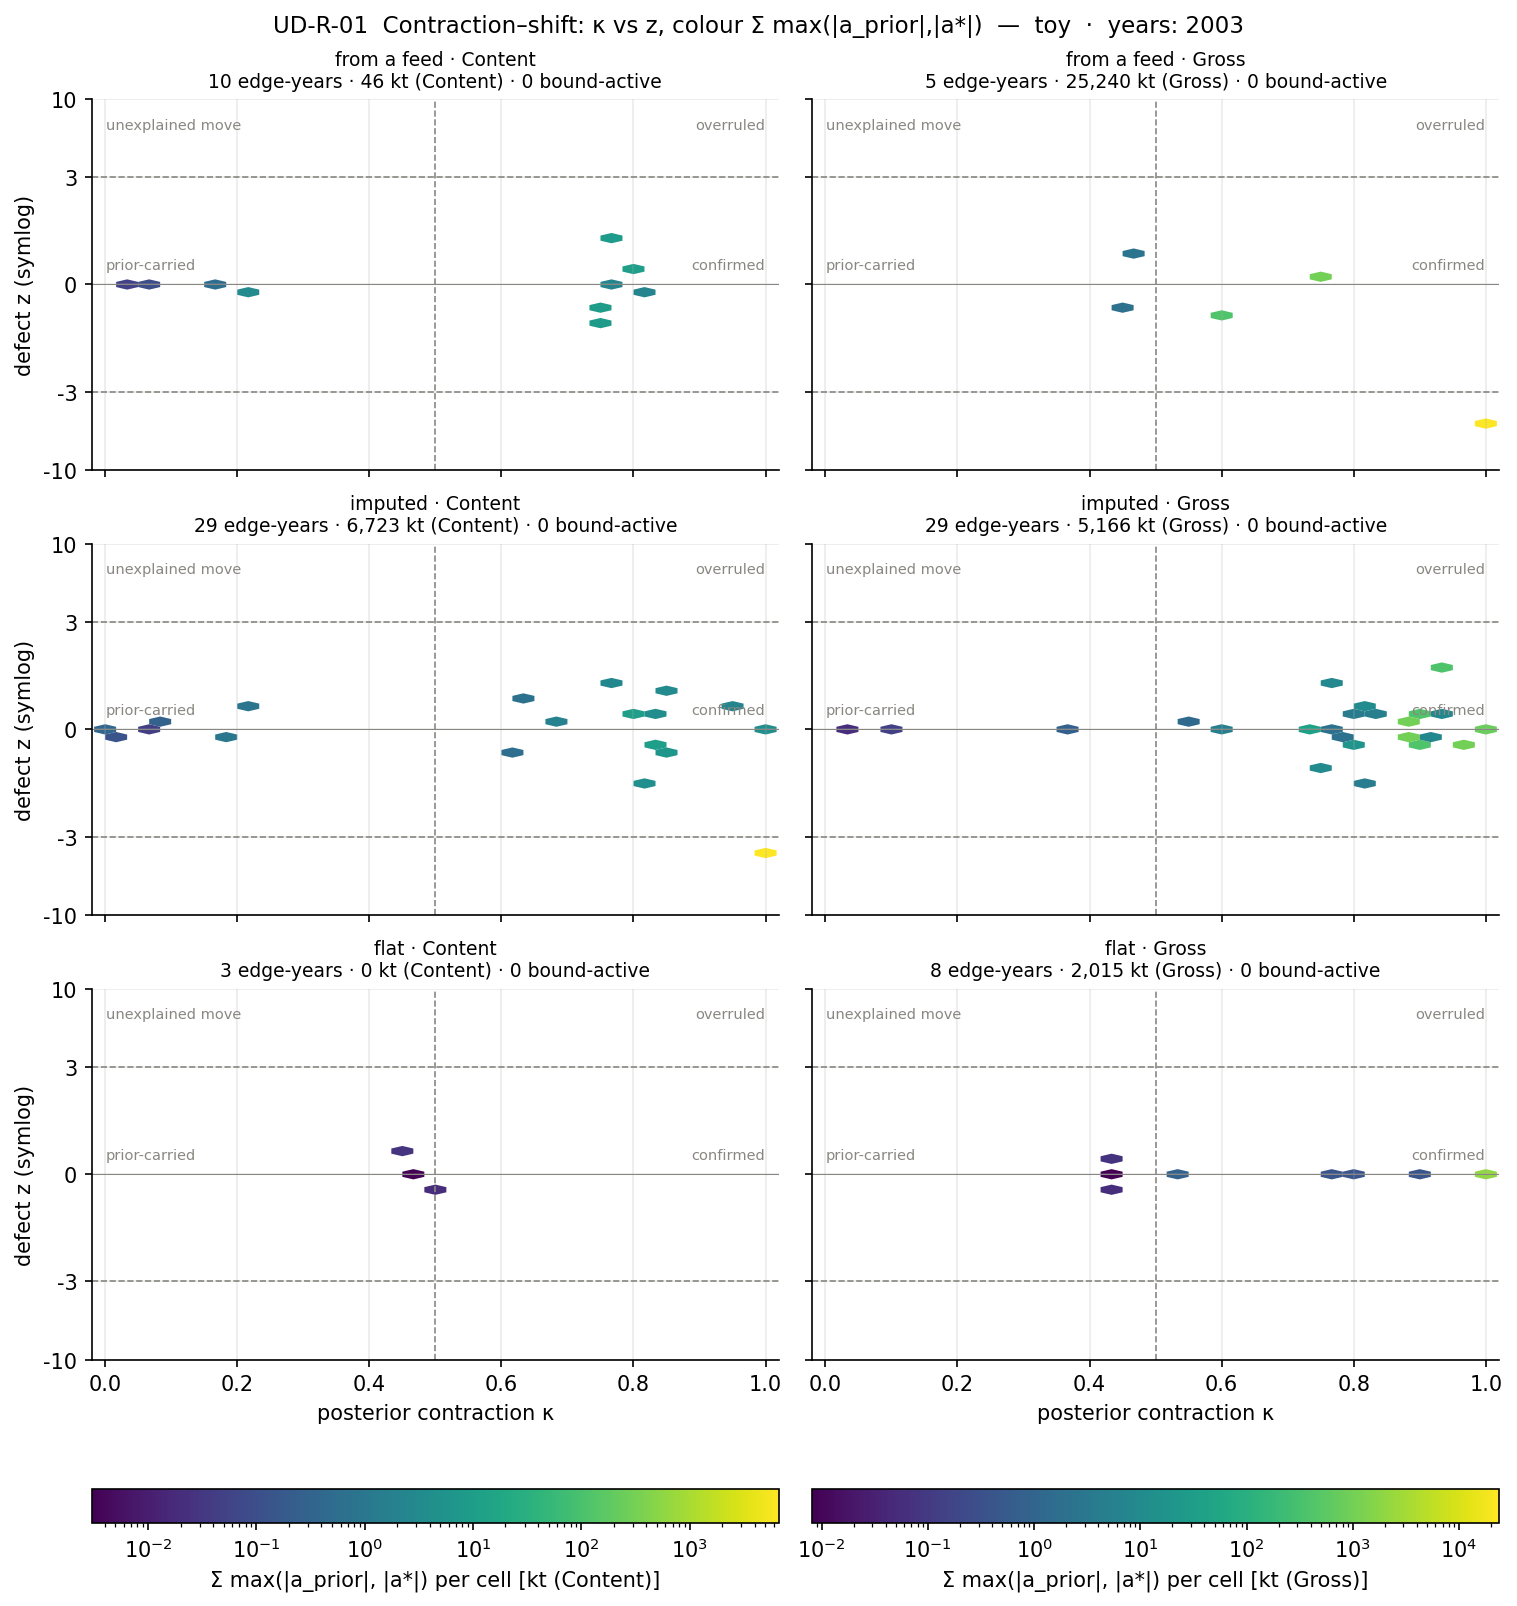

In [10]:
diag = UncPropDiag.from_uncprop_id(unc_id, uncprop_dir=str(PROC / "uncprop"), opt_dir=str(PROC / "opt"),
                                   const_dir=str(PROC / "const"), imp_dir=str(PROC / "imp"),
                                   label="toy", acc=acc, acc_dir=str(PROC / "acc"))
paths = diag.plot(odir=str(RUNS / "figs"), plot_ids=["UD-R-01", "UD-R-02"], timesteps=[year])
display(Image(str(RUNS / "figs" / "ud_r_01_contraction_shift.png")))

Right of the vertical line the rows dominate the edge (contraction above one half); left, the prior does. Above $|z|=3$ the edge moved by more than three of its own σ, which marks an edge the data overrule.

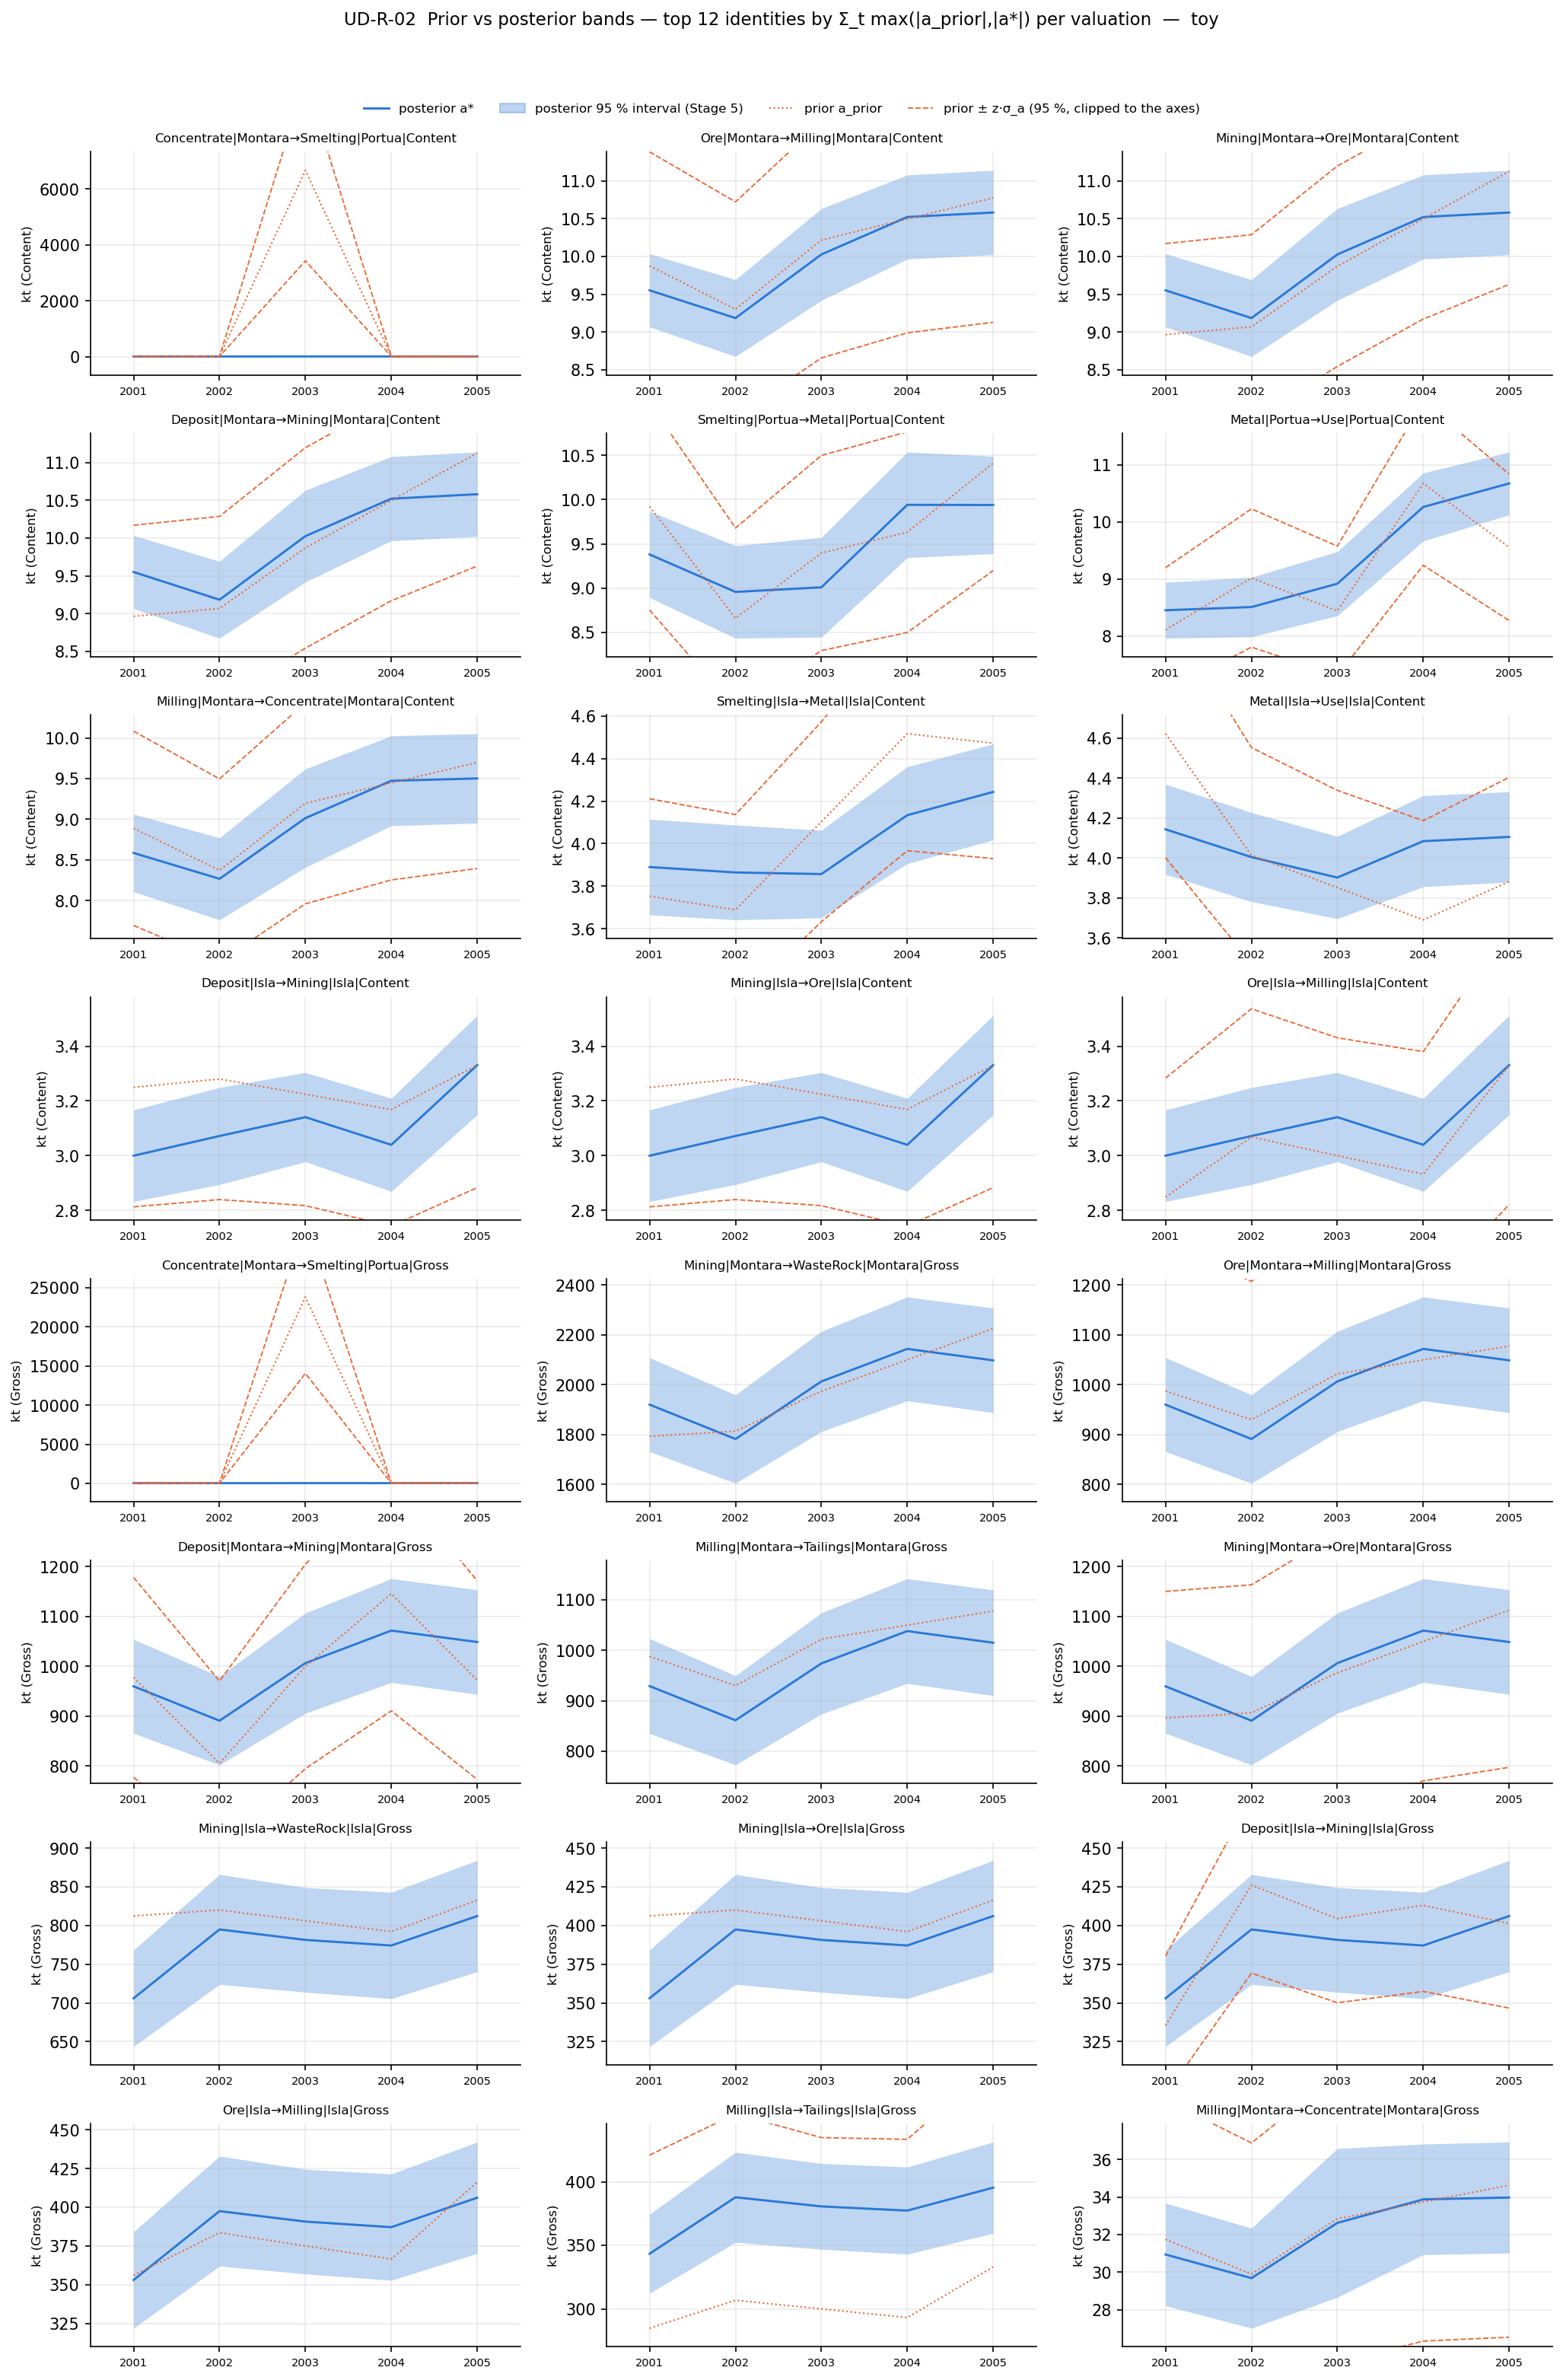

In [11]:
display(Image(str(RUNS / "figs" / "ud_r_02_prior_posterior_bands.png")))

Dashed: the prior's 95 % band. Filled: the posterior's. Where a prior band leaves the axes altogether, the prior was too wide to say anything and the posterior is the only informative band. Because the toy registers no non-negativity band, some of the filled bands reach below zero; copper's would be clipped there.

**Exercise 5.1** — From the table `shrink` above, find the largest ratio $\sigma_{a^*}/\sigma_a$ over every edge and year, and check it with `toy.check_5_1`. It must not exceed 1. Cover the next cell and try it first; `toy.solution("5.1")` prints the reference.

In [12]:
worst = shrink["ratio"].max()
print(f"largest ratio {worst:.6f} on {shrink.loc[shrink['ratio'].idxmax(), 'edge']}")
print(toy.check_5_1(RUNS, worst))

largest ratio 1.000000 on Mining|Montara → WasteRock|Montara (Content)
✓ 5.1  max σ_a*/σ_a = 1.0000 ≤ 1


## Where this run came from

In [13]:
meta = json.loads((PROC / "uncprop" / unc_id / "metadata.json").read_text())
print("parents.inputs  :", meta["parents"]["inputs"])
print("parents.upstream:", meta["parents"]["upstream"])

parents.inputs  : {}
parents.upstream: {'opt_run_id': 'opt_20261123_151908_06e888ed', 'const_run_id': 'const_20261123_151905_b9419350'}


The uncprop run names the opt run it propagates and the constraint run behind it. Next: [chapter 06](06_psut_piot.ipynb), where $a^*$ becomes supply–use tables.